In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [50]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/DL/Dataset/fmnist_small.csv')

In [51]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0


In [52]:
import numpy as np
import sklearn.model_selection as model_selection
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [53]:
# set random seeds for productivity
torch.manual_seed(42)


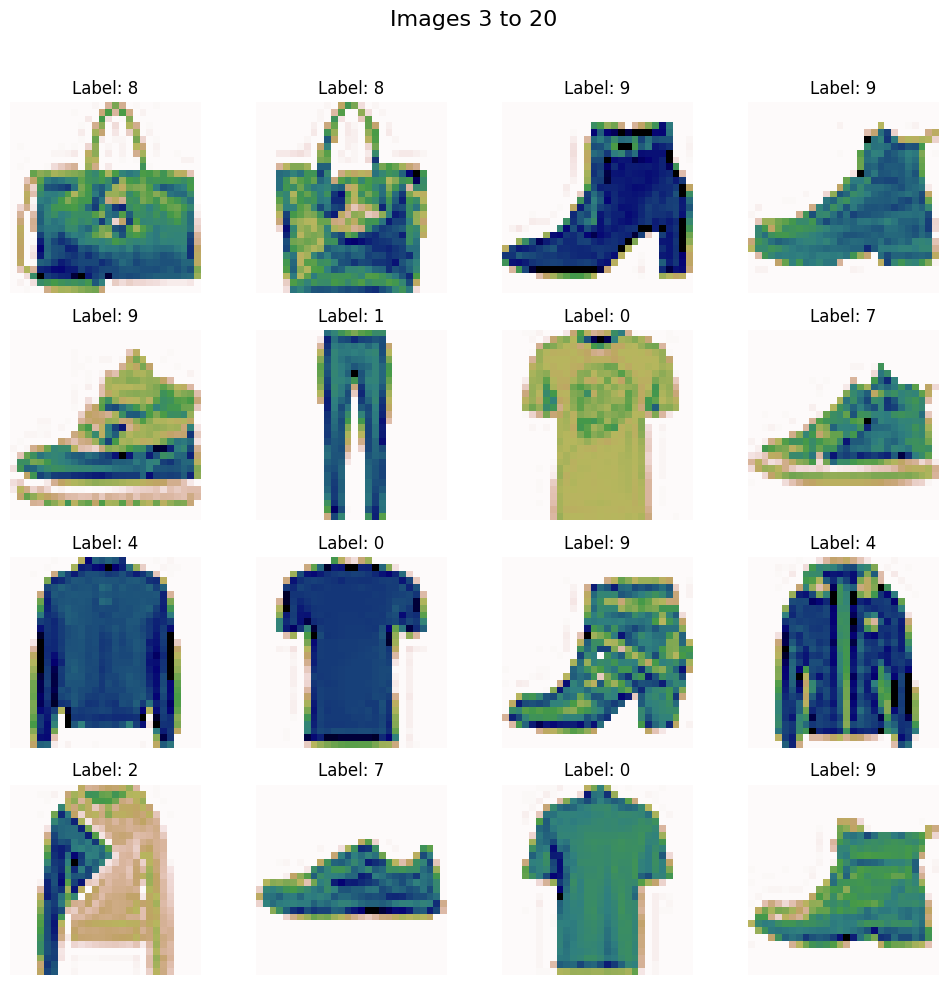

In [54]:
start = 3
end = 20              # last image to show (included)
n = end - start + 1   # 17 images

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle(f'Images {start} to {end}', fontsize=16)

for k, ax in enumerate(axes.flat):
  if k < n:
    i = start + k
    img = df.iloc[i, 1:].values.reshape(28, 28)
    ax.imshow(img, cmap='gist_earth_r')
    ax.set_title(f"Label: {df.iloc[i, 0]}")
  ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [55]:
# train test split

x = df.iloc[:, 1:].values
y = df.iloc[:, 0].values



In [56]:
x_train, x_test, y_train, y_test = model_selection.train_test_split(x, y, test_size=0.2, random_state=42)

In [57]:
print(x_train.shape)
print(y_train.shape)


(4800, 784)
(4800,)


In [58]:
x_train = x_train/255.0
x_test = x_test/255.0

In [59]:
x_train

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.0627451, 0.       ,
        0.       ]], shape=(4800, 784))

In [60]:
# Create custom dataset class
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]

In [61]:
# create train dataset object
train_dataset = CustomDataset(x_train, y_train)


In [62]:
train_dataset[0][1]

tensor(7)

In [63]:
# create test obj
test_dataset = CustomDataset(x_test, y_test)

In [64]:
# create train and test loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [65]:
# define NN class
class myNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )

  def forward(self, x):
    return self.model(x)

In [66]:
# Set learning rate and epochs
epochs = 100
learning_rate = 0.1

In [67]:
# initiate the model
model = myNN(num_features=len(x_train[0]))

# loss function
criterion = nn.CrossEntropyLoss()

# optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [68]:
train_loader.batch_size

32

In [69]:
# training loop
total_loss = 0.0
for epoch in range(epochs):
  total_epoch_loss = 0.0
  loss = 0.0
  for batch_features, batch_labels in train_loader:
    # forward pass
    outputs = model(batch_features)

    #calculate loss
    loss = criterion(outputs, batch_labels)

    optimizer.zero_grad()
    # backprop
    loss.backward()

    #update weights
    optimizer.step()

    total_epoch_loss += loss.item()

  total_loss += total_epoch_loss
  print(f"Epoch {epoch+1}/{epochs}, Loss: {total_epoch_loss/len(train_loader)}")

avg_loss = total_epoch_loss/len(train_loader)
print(f"Average Loss: {avg_loss}")



Epoch 1/100, Loss: 1.3216368440786999
Epoch 2/100, Loss: 0.7793365436792373
Epoch 3/100, Loss: 0.6427524652083715
Epoch 4/100, Loss: 0.5751657336950302
Epoch 5/100, Loss: 0.528180201848348
Epoch 6/100, Loss: 0.49528750121593473
Epoch 7/100, Loss: 0.4602432996034622
Epoch 8/100, Loss: 0.4359459094206492
Epoch 9/100, Loss: 0.41829214423894884
Epoch 10/100, Loss: 0.3984092291692893
Epoch 11/100, Loss: 0.3850264506538709
Epoch 12/100, Loss: 0.3722685620188713
Epoch 13/100, Loss: 0.3477362078428268
Epoch 14/100, Loss: 0.3467242218057315
Epoch 15/100, Loss: 0.3138812760512034
Epoch 16/100, Loss: 0.3126461291313171
Epoch 17/100, Loss: 0.29552092105150224
Epoch 18/100, Loss: 0.2857150869568189
Epoch 19/100, Loss: 0.27084775785605114
Epoch 20/100, Loss: 0.26237100958824155
Epoch 21/100, Loss: 0.25756089876095456
Epoch 22/100, Loss: 0.24232648963729542
Epoch 23/100, Loss: 0.23957946779827277
Epoch 24/100, Loss: 0.2261324493587017
Epoch 25/100, Loss: 0.2233684351791938
Epoch 26/100, Loss: 0.21165

In [71]:
# set model to eval model
model.eval()


myNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [73]:
# evalution code
total = 0.0
correct = 0.0
with torch.no_grad():
  for batch_features, batch_labels in test_loader:
    outputs = model(batch_features)

    predictions = torch.argmax(outputs, dim=1)
    total += batch_labels.size(0)
    correct += (predictions == batch_labels).sum().item()

accuracy = correct/total
print(f"Accuracy: {accuracy}")

Accuracy: 0.8325
